In [2733]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

data = pd.read_csv("salesdaily.csv")
drugs = ["M01AB", "M01AE", "N02BA", "N02BE", "N05B", "N05C", "R03", "R06"]
sales = pd.DataFrame()

sales["total"] = data[drugs].sum()
sales["total_jan_15"] = data[(data.Year == 2015) & (data.Month == 1)][drugs].sum()
sales["total_jul_16"] = data[(data.Year == 2016) & (data.Month == 7)][drugs].sum()
sales["total_sep_17"] = data[(data.Year == 2017) & (data.Month == 9)][drugs].sum()
sales["total_2017"] = data[data.Year == 2017][drugs].sum()
sales["mean_daily"] = data.groupby("datum")[drugs].sum().mean()
r03_monthly_sales = data.groupby("Month").R03.sum()

# What are the total sales quantities for each drug category (ATC code)?


In [2734]:
display(
    HTML(
        f"<h3>Total sales of each drug category</h3>\n{sales.total.to_frame().T.to_html(index=False)}"
    )
);


M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
10600.937083,8204.618646,8172.209,63005.402708,18645.7375,1249.958333,11608.822917,6107.8175


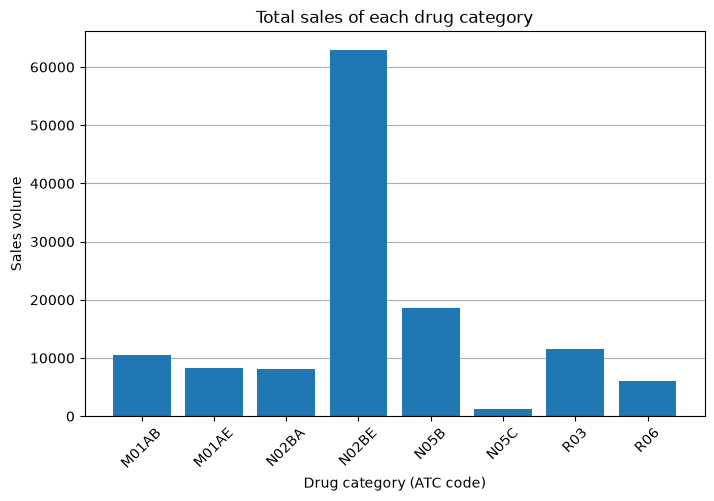

In [2735]:
plt.figure(figsize=(8, 5))
plt.title('Total sales of each drug category')
plt.xlabel('Drug category (ATC code)')
plt.ylabel('Sales volume')
plt.xticks(rotation=45)
plt.bar(
    sales.total.index, sales.total
),
plt.rc("axes", axisbelow=True)
plt.grid(axis="y", linestyle="-")
plt.show();

# Which individual drug brands have the highest total sales?

In [2736]:
display(
    HTML(
        f"<h3>Total sales of each drug category, sorted descending</h3>\n{sales.total.sort_values(ascending=False).to_frame().T.to_html(index=False)}"
    )
);


N02BE,N05B,R03,M01AB,M01AE,N02BA,R06,N05C
63005.402708,18645.7375,11608.822917,10600.937083,8204.618646,8172.209,6107.8175,1249.958333


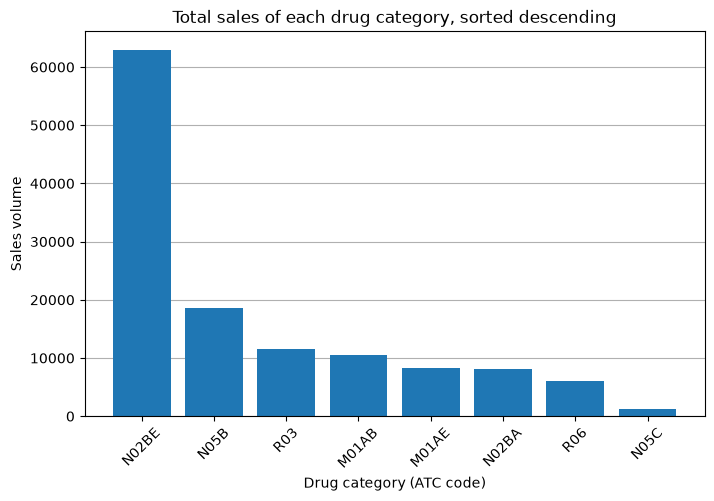

In [2737]:
plt.figure(figsize=(8, 5))
plt.title("Total sales of each drug category, sorted descending")
plt.xlabel("Drug category (ATC code)")
plt.ylabel("Sales volume")
plt.xticks(rotation=45)
plt.bar(
    sales.total.sort_values(ascending=False).index,
    sales.total.sort_values(ascending=False)
),
plt.rc("axes", axisbelow=True)
plt.grid(axis="y", linestyle="-")
plt.show();


# Which three drugs have the highest sales in Jan 2015, July 2016, and September 2017?

In [2738]:
display(
    HTML(
        f"<h3>Top 3 drug categories with highest sales: January 2015</h3>\n{sales.total_jan_15.nlargest(3).to_frame().T.to_html(index=False)}"
    )
)
display(
    HTML(
        f"<h3>Top 3 drug categories with highest sales: July 2016</h3>\n{sales.total_jul_16.nlargest(3).to_frame().T.to_html(index=False)}"
    )
)
display(
    HTML(
        f"<h3>Top 3 drug categories with highest sales: September 2017</h3>\n{sales.total_sep_17.nlargest(3).to_frame().T.to_html(index=False)}"
    )
)

N02BE,N05B,R03
1044.24,463.0,177.25


N02BE,N05B,M01AB
652.362,240.0,194.528333


N02BE,N05B,R03
863.75,223.0,139.0


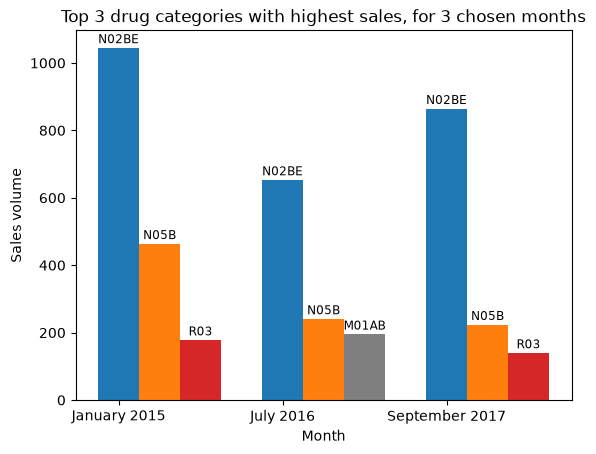

In [2739]:
plt.figure()
plt.title('Top 3 drug categories with highest sales, for 3 chosen months')
plt.xlabel('Month')
plt.ylabel('Sales volume')
colors = {d: f"C{k+7}" for k, d in enumerate(drugs)}
for i, col in enumerate(['total_jan_15', 'total_jul_16', 'total_sep_17']):
    top3 = sales[col].nlargest(3)
    x = i + (np.arange(3)) * 0.25
    plt.bar_label(
        plt.bar(x, top3.values, 0.25, color=[colors[d] for d in top3.index]),
        labels=top3.index,
        fontsize='small',
        padding=1.5
    )
plt.xticks(range(3), ["January 2015", "July 2016", "September 2017"])
plt.show()

# Which drug has sold the most often in 2017?

In [2740]:
display(
    HTML(
        f"""<h3>Total sales of each drug category, 2017, sorted descending</h3>
        {sales.total_2017.sort_values(ascending=False).to_frame().T.to_html(index=False)}
        <strong>{sales.total_2017.nlargest(1).index.values[0]} </strong> has the highest sales in 2017, with around <em>{sales.total_2017.nlargest(1).values[0]:,.0f}</em> sales."""
    )
)

N02BE,N05B,R03,M01AB,M01AE,N02BA,R06,N05C
9258.804833,2555.541667,1893.614583,1846.617083,1387.298333,1288.295833,988.86,180.333333


# Which drug category has the highest average daily sales?

In [2741]:
display(
    HTML(
        f"""<h3>Mean daily sales for each drug category, sorted descending</h3>
        {sales.mean_daily.sort_values(ascending=False).to_frame().T.to_html(index=False)}
        <strong>{sales.mean_daily.nlargest(1).index.values[0]}</strong> has the highest mean daily sales, with around <em>{sales.mean_daily.nlargest(1).values[0]:,.2f}</em> sales per day on average."""
    )
)

N02BE,N05B,R03,M01AB,M01AE,N02BA,R06,N05C
29.917095,8.853627,5.512262,5.033683,3.89583,3.880441,2.900198,0.593522


# Are respiratory drugs (R03) sold more during specific months?

In [2742]:
months = {1: "Jan",  2: "Feb",  3: "Mar",  4: "Apr",  5: "May",  6: "Jun",  7: "Jul",  8: "Aug",  9: "Sep",  10: "Oct",  11: "Nov",  12: "Dec"}
display(
    HTML(
        f"""<h3>Total monthly sales of respiratory (R03) drugs, 2014-2019</h3>
        {r03_monthly_sales.to_frame().rename(index=months).T.rename(index={"Month": "Month", "R03": "Total sales"}).to_html()}
        The months from <strong>October</strong> to <strong>March</strong> have the highest sales of respiratory drugs."""
    )
)

Month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Total sales,1264.65625,1165.583333,1170.0,1038.875,931.291667,783.0,550.0,577.0,792.416667,1175.0,934.0,1227.0


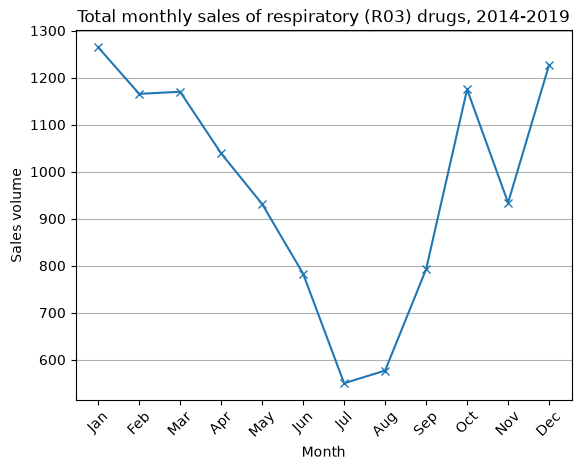

In [2743]:
plt.figure()
plt.plot(r03_monthly_sales.index, r03_monthly_sales, marker='x')
plt.title("Total monthly sales of respiratory (R03) drugs, 2014-2019")
plt.xlabel("Month")
plt.ylabel("Sales volume")
plt.xticks(range(1, 13), months.values(), rotation=45)
plt.rc('axes', axisbelow=True)
plt.grid(axis='y', linestyle='-')
plt.show()